<a href="https://colab.research.google.com/github/LsYoli/fisica_computacional/blob/main/TALLER4/taller_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# --- Bibliotecas ---
import random                    # generador pseudoaleatorio de la biblioteca estándar
import numpy as np               # arreglos numéricos (arreglos, lectura y visualización)
import matplotlib.pyplot as plt  # gráficas

## Parte A — Funciones de la simulación

Complete las tres funciones de la siguiente celda:

1. `generar_paso(rng,a)`: consuma **un** número del generador recibido y devuelva $+a$ o $-a$.
2. `caminar(N,a,rng)`: valide $N\geq0$ y $a>0$; devuelva **$N+1$ posiciones**, incluida $x_0=0$.
3. `simular_caminatas(K,N,a,semilla,generador=None)`: valide $K>0$, $N\geq0$ y $a>0$. Si `generador` es `None`, cree **un solo** `random.Random(semilla)` al inicio; si se entrega un generador, úselo en su lugar (lo necesitará en la Parte D). Pase ese mismo generador a cada caminata y acumule $x_n$ y $x_n^2$ para todos los $n$.
4. Divida cada suma por $K$ **después** del ciclo sobre caminantes. Devuelva `(media_x, media_x2)`.

Use `ValueError` para parámetros inválidos. No reinicie la semilla dentro del ciclo de caminantes: eso repetiría la misma trayectoria $K$ veces.

<div style="background-color:#eef7ee; border-left:5px solid #4caf50; padding:10px 15px; margin:10px 0;"><b>Prueba manual:</b> para <code>N=0</code>, la trayectoria y ambos promedios deben contener solamente el cero inicial.</div>

In [2]:
def generar_paso(rng, a):
    """Un paso de longitud a: derecha si u<0.5, izquierda si u>=0.5."""
    # TODO: obtenga u con rng.random() y devuelva el paso correspondiente.
    u = rng.random()      # Número uniforme en [0, 1) tomado del generador recibido.
    if u < 0.5:
      return a            # Mitad inferior del intervalo: paso a la derecha (+a).

    elif u >= 0.5:
      return -a           # Mitad superior: paso a la izquierda (-a).
                          # Cada paso consume exactamente un número del generador.


def caminar(N, a, rng):
    """Construye [x_0, x_1, ..., x_N] a partir del generador recibido."""
    # TODO: valide los parámetros; empiece con x=0 y posiciones=[0].
    # En cada iteración llame a generar_paso, actualice x y guarde x.

    # Validación: N=0 es válido (la caminata es solo el origen); a debe ser positivo.
    if N < 0:
      raise ValueError("N debe ser >= 0")
    if a <= 0:
      raise ValueError("a debe ser > 0")

    # Lista de N+1 posiciones ya inicializadas en 0.0; caminata[0] = x_0 = 0 queda lista.
    caminata =[0.0]*(N+ 1)

    # Cada posición es la anterior más un paso nuevo: x_n = x_{n-1} + s_n.
    for n in range (1, N+1):
      caminata[n]= caminata[n-1] + generar_paso(rng, a)
    return caminata   # Trayectoria completa [x_0, x_1, ..., x_N].


def simular_caminatas(K, N, a, semilla, generador=None):

    """Promedia x_n y x_n² en K caminatas; incluye el índice n=0.

    Si generador es None se usa random.Random(semilla); en caso contrario se
    usa el objeto recibido, que solo necesita un método random() en [0, 1).
    """
    # TODO: valide los parámetros.
    # Si generador es None, construya rng=random.Random(semilla);
    # si no, use rng=generador.
    # Cree dos arreglos de N+1 ceros. Para cada caminante:
    #   trayectoria = caminar(N, a, rng)
    #   para cada n, agregue trayectoria[n] y trayectoria[n]**2.
    # Divida los acumuladores por K y devuelva ambos promedios.

    # Validación de parámetros: K es el número de caminatas, N los pasos, a la longitud del paso.
    if K <= 0:
      raise ValueError("K debe ser > 0")
    if N < 0:
      raise ValueError("N debe ser >= 0")
    if a <= 0:
      raise ValueError("a debe ser > 0")

    # Un solo generador para todas las caminatas (no se reinicia la semilla)
    # Si se entrega un generador (por ejemplo, uno deficiente para la Parte D), se usa ese.
    if generador is None:
      rng = random.Random(semilla)
    else:
      rng = generador

    # Acumuladores: suma_x[n] y suma_x2[n] sumarán x_n y x_n² sobre las K caminatas.
    suma_x = [0.0] * (N + 1)
    suma_x2 = [0.0] * (N + 1)

    # Ciclo externo: una caminata nueva por iteración. Como rng es el mismo objeto,
    # cada caminata consume números distintos y sale una trayectoria diferente.
    for _ in range(K):
      trayectoria = caminar(N, a, rng)

      # Ciclo interno: se suma la posición y su cuadrado en cada instante n (incluido n=0).
      for n in range(N + 1):
        suma_x[n] += trayectoria[n]
        suma_x2[n] += trayectoria[n] ** 2   # Se eleva al cuadrado antes de promediar.

    # Se divide entre K (número de caminatas) una sola vez, al final.
    media_x = np.array(suma_x)/K      # <x_n>: debería quedar cerca de 0.
    media_x2 = np.array(suma_x2)/K    # <x_n²>: debería ser aprox. n·a².

    return media_x, media_x2






In [6]:
# --- Prueba manual: N=0 ---
# La trayectoria y ambos promedios deben contener solamente el cero inicial.

tray_0 = caminar(0, 1.0, random.Random(1))
mx_0, mx2_0 = simular_caminatas(5, 0, 1.0, semilla=1)

print("Trayectoria:", tray_0)       # esperado: [0.0]
print("media_x:", mx_0)             # esperado: [0.]
print("media_x2:", mx2_0)           # esperado: [0.]

# Verificación automática
assert tray_0 == [0.0]
assert len(mx_0) == 1 and mx_0[0] == 0.0
assert len(mx2_0) == 1 and mx2_0[0] == 0.0
print("Prueba N=0 superada")

Trayectoria: [0.0]
media_x: [0.]
media_x2: [0.]
Prueba N=0 superada


## Parte B — Ajuste y coeficiente de difusión

Complete el ajuste con las sumas de la sección 4. La función debe devolver `(pendiente, intercepto)` y usar `ValueError` si las listas tienen distinta longitud, hay menos de dos puntos o el denominador es cero. No sustituya el ajuste por una llamada a `np.polyfit`. Compruebe primero el ejemplo exacto $y=3x+2$ y luego úselo con los valores simulados de $\langle x_n^2\rangle$.

In [3]:
def ajuste_lineal(x, y):
    """Ajuste y=m*x+b con sumas explícitas; devuelve (m, b)."""
    # Validación: las dos listas deben tener el mismo número de puntos
    if len(x) != len(y):
        raise ValueError("x e y deben tener la misma longitud")
    # Con menos de dos puntos no se puede definir una recta
    if len(x) < 2:
        raise ValueError("se necesitan al menos dos puntos")

    # --- Sumas de mínimos cuadrados (las mismas de la semana 3) ---
    q = len(x)                               # número de puntos
    sx, sy = sum(x), sum(y)                  # suma de x y suma de y
    sxx = sum(valor*valor for valor in x)    # suma de x^2
    sxy = sum(u*v for u, v in zip(x, y))     # suma de x*y

    # --- Pendiente e intercepto ---
    denominador = q*sxx - sx*sx
    # Denominador cero: todos los x son iguales, la pendiente no está definida
    if denominador == 0:
        raise ValueError("denominador cero: los valores de x no pueden ser todos iguales")
    m = (q*sxy - sx*sy)/denominador
    b = (sy - m*sx)/q

    return m, b




In [7]:
# --- Ejemplo exacto: y = 3x + 2 ---
x_ej = [0.0, 1.0, 2.0, 3.0]
y_ej = [2.0, 5.0, 8.0, 11.0]

m_ej, b_ej = ajuste_lineal(x_ej, y_ej)
print(f"Ejemplo exacto: m={m_ej}, b={b_ej}")   # esperado: m=3.0, b=2.0

# --- Uso con los valores simulados de <x_n^2> ---
K_prueba, N_prueba = 2000, 50
_, media_x2_prueba = simular_caminatas(K_prueba, N_prueba, 1.0, semilla=11)

m_sim, b_sim = ajuste_lineal(list(range(N_prueba + 1)), media_x2_prueba)
print(f"Datos simulados: m={m_sim:.5f}, b={b_sim:.5f}")   # esperado: m ~ 1, b ~ 0

Ejemplo exacto: m=3.0, b=2.0
Datos simulados: m=1.03789, b=-0.31031


El ejemplo exacto y = 3x + 2 devolvió m = 3.0 y b = 2.0, lo que valida la función ajuste_lineal.

Con los datos simulados (K = 2000, N = 50, a = 1) se obtuvo m = 1.03789 y b = −0.31031, frente a los valores teóricos m = 1 y b = 0. La pendiente se desvía cerca de un 3.8 %, y el intercepto es pequeño frente a la escala de ⟨xₙ²⟩ (hasta ~50). La diferencia se debe al error estadístico de usar un número finito de caminatas: la dispersión de ⟨xₙ²⟩ crece con n y esos puntos desplazan la recta, por eso m queda algo mayor que 1 y b algo menor que 0. Este error debería disminuir al aumentar K.

El crecimiento lineal de ⟨xₙ²⟩ con n confirma un comportamiento difusivo, y la pendiente permite estimar D = m/(2Δt).

## Parte C — Ejecutar, guardar y graficar

Complete los dos espacios de la celda siguiente y ejecútela después de terminar las funciones. El archivo CSV debe contener las columnas `n,media_x,media_x2,ajuste`, una fila por cada paso **incluido $n=0$**. En la figura muestre una caminata individual y, en otro panel, los valores promediados, la recta ajustada y la predicción teórica.

Reporte pendiente, intercepto y coeficiente de difusión $D$ con unidades. Aquí $a=1$ unidad de longitud y $\Delta t=1$ unidad de tiempo, de modo que el resultado de referencia es $D=0.5$ longitud$^2$/tiempo. Su valor simulado no tiene que coincidir exactamente. El valor de $D$ del informe debe proceder de `ajuste_lineal`.

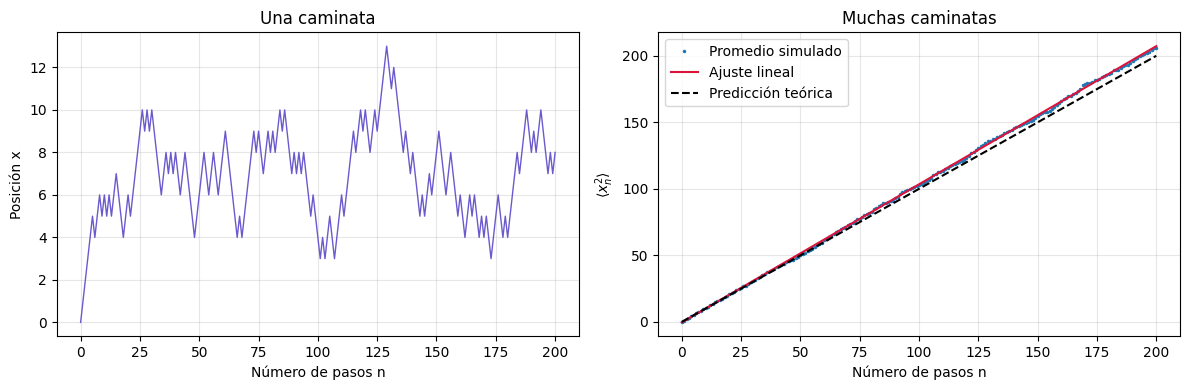

Pendiente = 1.03839 (unidades de longitud² por paso)
Intercepto = -0.40870 (unidades de longitud²)
D estimado = 0.51919 longitud²/tiempo
D teórico  = 0.50000 longitud²/tiempo
Diferencia relativa = 3.84 %


In [8]:
# --- Parámetros del experimento ---
K, N = 2000, 200            # caminantes y pasos por caminante
a, delta_t = 1.0, 1.0       # longitud de paso e intervalo de tiempo
semilla = 2026              # semilla del resultado entregado

# --- Simulación y ajuste lineal de <x_n^2> frente a n ---
media_x, media_x2 = simular_caminatas(K, N, a, semilla)
pasos = list(range(N + 1))
pendiente, intercepto = ajuste_lineal(pasos, media_x2)

# --- Coeficiente de difusión: estimado (del ajuste) y teórico ---
D_estimado = pendiente / (2 * delta_t) # pendiente / (2*delta_t)
D_teorico = a * a / (2 * delta_t)  # a*a / (2*delta_t)
ajuste = [pendiente*n + intercepto for n in pasos]   # recta ajustada, para graficar

# --- Una trayectoria individual, para comparar con el promedio ---
# La semilla distinta permite mostrar una trayectoria reproducible e independiente.
trayectoria = caminar(N, a, random.Random(2027))

# --- Guardar los resultados en un archivo CSV ---
with open("caminata_difusion.csv", "w", encoding="utf-8") as archivo:
    archivo.write("n,media_x,media_x2,ajuste\n")
    for n in pasos:
        archivo.write(f"{n},{media_x[n]},{media_x2[n]},{ajuste[n]}\n")

# --- Figura: trayectoria individual (izquierda) y promedios (derecha) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(pasos, trayectoria, color="slateblue", linewidth=1)
ax1.set(xlabel="Número de pasos n", ylabel="Posición x", title="Una caminata")
ax2.plot(pasos, media_x2, ".", markersize=3, label="Promedio simulado")
ax2.plot(pasos, ajuste, color="crimson", label="Ajuste lineal")
ax2.plot(pasos, [n*a*a for n in pasos], "--", color="black", label="Predicción teórica")
ax2.set(xlabel="Número de pasos n", ylabel=r"$\langle x_n^2\rangle$", title="Muchas caminatas")
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
ax2.legend()
plt.tight_layout()
plt.savefig("caminata_difusion.png", dpi=180, bbox_inches="tight")
plt.show()

# --- Resumen numérico con unidades ---
print(f"Pendiente = {pendiente:.5f} (unidades de longitud² por paso)")
print(f"Intercepto = {intercepto:.5f} (unidades de longitud²)")
print(f"D estimado = {D_estimado:.5f} longitud²/tiempo")
print(f"D teórico  = {D_teorico:.5f} longitud²/tiempo")

In [9]:
# --- Exploración: efecto del número de caminantes K sobre D ---
N, a, delta_t, semilla = 200, 1.0, 1.0, 2026
D_teorico = a*a / (2*delta_t)
pasos = list(range(N + 1))

print(f"{'K':>6} {'pendiente':>10} {'intercepto':>11} {'D estimado':>11} {'error rel. (%)':>15}")
for K in (100, 2000):
    _, media_x2 = simular_caminatas(K, N, a, semilla)
    m, b = ajuste_lineal(pasos, media_x2)
    D = m / (2*delta_t)                      # D sale de la pendiente de ajuste_lineal
    error = abs(D - D_teorico)/D_teorico*100
    print(f"{K:>6} {m:>10.5f} {b:>11.5f} {D:>11.5f} {error:>15.2f}")

print(f"D teórico = {D_teorico} longitud²/tiempo (semilla = {semilla})")

     K  pendiente  intercepto  D estimado  error rel. (%)
   100    1.33523   -11.74962     0.66761           33.52
  2000    1.03839    -0.40870     0.51919            3.84
D teórico = 0.5 longitud²/tiempo (semilla = 2026)


Cada valor de D estimado es una sola realización de una variable aleatoria: depende de las K trayectorias concretas que salieron del generador. El error típico de ese estimador disminuye aproximadamente como 1/√K, así que pasar de K = 100 a K = 2000 debería reducirlo en un factor cercano a 4.5. Sin embargo, “típico” habla de lo que pasa en promedio sobre muchas repeticiones, no de lo que pasa en una ejecución puntual. Con solo dos ejecuciones, una realización con K = 100 puede quedar por casualidad más cerca de D = 0.5 que una con K = 2000, aunque la segunda tenga menor dispersión esperada. Además, al conservar la semilla, las 100 caminatas de la primera simulación son las mismas primeras 100 de la segunda, de modo que no son experimentos independientes. Para ver la mejora de forma clara habría que repetir cada K con varias semillas y comparar la dispersión de los D obtenidos, no un único valor.

Una trayectoria individual es muy irregular: en cada paso la partícula sube o baja de forma aleatoria, y su posición después de n pasos es del orden de ±a√n, sin seguir ninguna recta ni repetirse de una caminata a otra. Esas son las fluctuaciones de una realización. El promedio ⟨xₙ²⟩ sobre K caminatas, en cambio, suaviza esas fluctuaciones porque las desviaciones positivas y negativas de cada trayectoria se compensan, y deja ver la tendencia determinista ⟨xₙ²⟩ = n a². Por eso en la figura la caminata individual (panel izquierdo) es errática, mientras que el promedio (panel derecho) es casi una recta. El promedio no queda libre de ruido: al usar un número finito de caminatas, su error disminuye aproximadamente como 1/√K, y por eso la pendiente simulada (1.038) se desvía un poco del valor teórico (1).

## Parte D — Efecto de un mal generador sobre el coeficiente de difusión

En las diapositivas se mostró que el generador congruencial $(a,c,M,r_1)=(57,1,256,10)$ produce pares consecutivos alineados en una rejilla. Ahora se medirá el efecto de ese defecto sobre **un resultado físico**: el coeficiente de difusión $D$.

La clase `GeneradorLCG` de la celda siguiente ya está completa. Tiene un método `random()` que devuelve $r_i/M$, igual que `random.Random`; por eso puede entregarse directamente a `simular_caminatas` mediante el argumento `generador`. Ejecútela sin modificarla.

### Actividades

1. Ejecute la simulación con $K=2000$, $N=200$, $a=1$, $\Delta t=1$ usando tres generadores: `random.Random(2026)`, el LCG deficiente `GeneradorLCG(57, 1, 256, 10)` y el LCG de parámetros de `drand48`, `GeneradorLCG(0x5DEECE66D, 11, 2**48, 10)`.
2. Ajuste una recta a $\langle x_n^2\rangle$ en cada caso con `ajuste_lineal` y calcule el coeficiente de difusión $D$. Guarde los resultados en `D_lcg_malo` y `D_drand48`.
3. Represente $\langle x_n^2\rangle$ frente a $n$ para los tres generadores en una misma figura.
4. Guarde en `trayectoria_lcg_larga` **una sola** caminata de 1024 pasos con el LCG deficiente e imprima la posición en $n = 0, 256, 512, 768, 1024$. Explique el resultado usando el período del generador.
5. Responda: ¿qué coeficiente de difusión habría reportado un investigador que usara este generador sin probarlo? ¿Por qué las pruebas de media y de pares consecutivos del Ejercicio 1 son necesarias antes de simular?


In [10]:
class GeneradorLCG:
    """Generador lineal congruente r_{i+1} = (a r_i + c) mod M.

    El método random() devuelve r/M en [0, 1), con la misma interfaz que
    random.Random, de modo que puede reemplazarlo en simular_caminatas.
    """

    # --- Constructor: guarda los parámetros y el estado inicial (la semilla) ---
    def __init__(self, a, c, M, semilla):
        self.a, self.c, self.M = a, c, M
        self.r = semilla % M          # el estado siempre está en 0, ..., M-1

    # --- Un número nuevo: actualiza el estado y lo escala a [0, 1) ---
    def random(self):
        self.r = (self.a*self.r + self.c) % self.M   # recurrencia congruencial
        return self.r / self.M                       # división real


# --- Comprobación con la secuencia de las diapositivas (a=4, c=1, M=9, r1=3) ---
demo = GeneradorLCG(4, 1, 9, 3)
print([round(demo.random()*9) for _ in range(9)])  # debe dar 4, 8, 6, 7, 2, 0, 1, 5, 3


[4, 8, 6, 7, 2, 0, 1, 5, 3]


D con random.Random : 0.5192
D con LCG deficiente: 0.0862
D con LCG drand48   : 0.4855   (teórico 0.5)


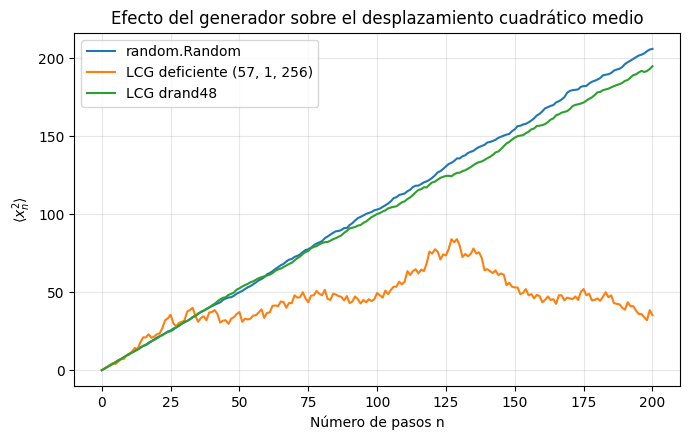

[0.0, 0.0, 0.0, 0.0, 0.0]


In [11]:
# --- Parámetros comunes a los tres experimentos ---
K_gen, N_gen = 2000, 200
pasos_gen = list(range(N_gen + 1))

# --- Misma simulación con tres generadores distintos ---
_, x2_bueno = simular_caminatas(K_gen, N_gen, 1.0, 2026)                                          # random.Random
_, x2_malo = simular_caminatas(K_gen, N_gen, 1.0, None, generador=GeneradorLCG(57, 1, 256, 10))   # LCG (57, 1, 256, 10)
_, x2_drand48 = simular_caminatas(K_gen, N_gen, 1.0, None,
                                  generador=GeneradorLCG(0x5DEECE66D, 11, 2**48, 10))            # LCG de drand48, semilla 10

# --- Pendiente de <x_n^2> para cada generador ---
m_bueno, _ = ajuste_lineal(pasos_gen, x2_bueno)
m_malo, _ = ajuste_lineal(pasos_gen, x2_malo)
m_drand48, _ = ajuste_lineal(pasos_gen, x2_drand48)

# --- Coeficiente de difusión D = pendiente / (2 dt), con dt = 1 ---
D_bueno = m_bueno/2
D_lcg_malo = m_malo/2
D_drand48 = m_drand48/2
print(f"D con random.Random : {D_bueno:.4f}")
print(f"D con LCG deficiente: {D_lcg_malo:.4f}")
print(f"D con LCG drand48   : {D_drand48:.4f}   (teórico 0.5)")

# --- Gráfica comparativa ---
plt.figure(figsize=(7, 4.5))
plt.plot(pasos_gen, x2_bueno, label="random.Random")
plt.plot(pasos_gen, x2_malo, label="LCG deficiente (57, 1, 256)")
plt.plot(pasos_gen, x2_drand48, label="LCG drand48")
plt.xlabel("Número de pasos n")
plt.ylabel(r"$\langle x_n^2\rangle$")
plt.title("Efecto del generador sobre el desplazamiento cuadrático medio")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# --- Una caminata larga con el LCG deficiente (actividad 4) ---
# Guarde la caminata completa para que PASS/FAIL pueda revisarla.
trayectoria_lcg_larga = caminar(1024, 1.0, GeneradorLCG(57, 1, 256, 10))
print([trayectoria_lcg_larga[n] for n in (0, 256, 512, 768, 1024)])

**Actividad 4: caminata larga con el LCG deficiente**

Las posiciones en n = 0, 256, 512, 768 y 1024 fueron todas 0.0. El generador (57, 1, 256) tiene período completo de 256: en cada bloque de 256 números aparece cada valor de r exactamente una vez. De esos valores, 128 quedan por debajo de 0.5·M (paso a la derecha) y 128 por encima o iguales (paso a la izquierda), de modo que cada bloque suma cero y la caminata regresa al origen en cada múltiplo de 256. Además, la trayectoria se repite idéntica cada 256 pasos. En una caminata aleatoria real, la posición después de 256 pasos sería del orden de ±16, no exactamente 0.

**Actividad 5: el investigador y las pruebas previas**

Un investigador que usara este generador sin probarlo habría reportado D ≈ 0.086 longitud²/tiempo, unas seis veces menor que el valor correcto de 0.5. No habría tenido ninguna señal de alarma: el código corre sin errores, el ajuste lineal devuelve un número y la simulación parece normal. El resultado sería una conclusión física falsa, una difusión mucho más lenta de la real.

Las pruebas de media y de pares consecutivos del Ejercicio 1 son necesarias antes de simular porque revisan las propiedades en las que se apoya el modelo: que los números sean uniformes y, sobre todo, independientes. La deducción ⟨xₙ²⟩ = n a² exige que los términos cruzados ⟨sᵢsⱼ⟩ se anulen, y eso solo ocurre si los pasos no están correlacionados. En este LCG los pasos están fuertemente correlacionados, los términos cruzados no se anulan y el resultado físico se distorsiona. Conviene notar que la prueba de media sola no lo detectaría, porque un LCG de período completo tiene media casi exacta de 0.5. Lo delatan los pares consecutivos (rᵢ, rᵢ₊₁), que caen alineados en una rejilla. Probar el generador antes de simular detecta el defecto con un costo mínimo, en lugar de descubrirlo, o no descubrirlo, a partir de un resultado físico equivocado.

## Parte E — Difusión en unidades reales

Hasta ahora $a=1$ y $\Delta t=1$ en unidades arbitrarias. Para dar sentido físico al resultado, considere una molécula de oxígeno disuelta en agua a temperatura ambiente, cuyo coeficiente de difusión $D$ es aproximadamente

$$D_{\rm O_2}\approx 2\times10^{-9}\ \text{m}^2/\text{s}.$$

El modelo de caminata reproduce ese valor si la longitud del paso y el intervalo cumplen $D=a^2/(2\Delta t)$. El tiempo característico para que el desplazamiento cuadrático medio alcance $L^2$ es, en una dimensión,

$$t(L)\approx\frac{L^2}{2D}.$$

### Actividades

1. Con $\Delta t = 1\ \mu\text{s}$, calcule la longitud de paso `a_fisico` (en metros) que reproduce $D_{\rm O_2}$.
2. Convierta la pendiente `pendiente` obtenida en la Parte C (en unidades de $a^2$ por paso) a un coeficiente de difusión en m²/s: $D_{\rm sim} = m\,a_{\rm fisico}^2/(2\Delta t)$. Compárelo con $D_{\rm O_2}$.
3. Calcule `t_celula`, `t_mm` y `t_cm`: el tiempo para difundir $L = 10\ \mu\text{m}$ (el tamaño de una célula), $1$ mm y $1$ cm. Exprese cada uno en la unidad más legible (s, min, h).
4. Calcule también el tiempo para $L = 1$ m en agua quieta y expréselo en años.
5. ¿Cuántos pasos $N$ necesitaría la simulación para representar la difusión a lo largo de 1 cm con el paso `a_fisico`? Comente por qué, a escalas grandes, se usa la ecuación de difusión en lugar de simular cada paso.
6. Discuta brevemente: la difusión basta para transportar oxígeno dentro de una célula, pero ¿basta para mezclar un contaminante en un lago? ¿Qué otro mecanismo de transporte domina a escalas grandes?


**Interpretación:** este tiempo corresponde a una distancia raíz cuadrática media $x_{\mathrm{rms}}=L$. No es el tiempo en que todas las partículas alcanzan $L$, ni garantiza mezcla completa. El paso `a_fisico` es una longitud efectiva de este modelo: no se identifica necesariamente con la distancia entre colisiones moleculares. El valor de $D_{\rm O_2}$ se usa como dato aproximado del ejercicio; depende de las condiciones del medio.


In [12]:
# --- Datos físicos (todo en unidades del SI) ---
D_O2 = 2e-9          # m^2/s, coeficiente de difusión del oxígeno en agua (aprox.)
dt_fisico = 1e-6     # s, intervalo de tiempo entre pasos

# --- Longitud de paso y coeficiente de difusión simulado ---
# De D = a^2/(2 dt) se despeja a = sqrt(2 D dt)
a_fisico = (2 * D_O2 * dt_fisico) ** 0.5     # m, longitud de paso que reproduce D_O2

# La pendiente de la Parte C está en unidades de a^2 por paso:
# D_sim = m * a_fisico^2 / (2 dt)
D_sim = pendiente * a_fisico**2 / (2 * dt_fisico)   # m^2/s, a partir de la pendiente de la Parte C

# --- Tiempo característico de difusión ---
def tiempo_difusion(L, D):
    """Tiempo t = L^2/(2D) para alcanzar una distancia RMS L en una dimensión."""
    return L**2 / (2 * D)    # despeje de <x^2> = 2 D t con <x^2> = L^2

# --- Tiempos para distintas escalas de longitud ---
t_celula = tiempo_difusion(10e-6, D_O2)   # s, una célula (10 µm)
t_mm = tiempo_difusion(1e-3, D_O2)        # s, 1 mm
t_cm = tiempo_difusion(1e-2, D_O2)        # s, 1 cm
t_m = tiempo_difusion(1.0, D_O2)          # s, 1 m

# --- Número de pasos que exigiría simular 1 cm con el paso a_fisico ---
# Cada paso dura dt_fisico, así que N = t / dt  (equivale a (L/a)^2)
N_cm = t_cm / dt_fisico

# --- Resultados en unidades legibles ---
print(f"a = {a_fisico*1e9:.1f} nm;  D_sim = {D_sim:.3e} m^2/s  (referencia {D_O2:.1e})")
print(f"10 µm: {t_celula:.3g} s")
print(f"1 mm : {t_mm:.3g} s = {t_mm/60:.3g} min")
print(f"1 cm : {t_cm:.3g} s = {t_cm/3600:.3g} h")
print(f"1 m  : {t_m/(3600*24*365.25):.3g} años")
print(f"Pasos para 1 cm: {N_cm:.2e}")

a = 63.2 nm;  D_sim = 2.077e-09 m^2/s  (referencia 2.0e-09)
10 µm: 0.025 s
1 mm : 250 s = 4.17 min
1 cm : 2.5e+04 s = 6.94 h
1 m  : 7.92 años
Pasos para 1 cm: 2.50e+10


**Actividad 1: longitud de paso**

a_fisico = √(4×10⁻¹⁵ m²) ≈ 6.32×10⁻⁸ m ≈ 63.2 nm.

**Actividad 2: D simulado y comparación**

D_sim = 2.077×10⁻⁹ m²/s, frente a D_O₂ = 2×10⁻⁹ m²/s.

Es un 3.8 % mayor. La diferencia viene del número finito de caminatas (K = 2000), no de un error físico.

**Actividad 3: tiempos de difusión (t = L²/2D)**

Célula, 10 µm: t_celula = 0.025 s (25 ms)
1 mm: t_mm = 250 s = 4.17 min
1 cm: t_cm = 2.5×10⁴ s = 6.94 h

Como t ∝ L², multiplicar la distancia por 10 multiplica el tiempo por 100.

**Actividad 4: 1 m en agua quieta**

t = 2.5×10⁸ s ≈ 7.92 años.

**Actividad 5: pasos para 1 cm**

N = t_cm/Δt = (L/a)² = 2.50×10¹⁰ pasos por caminata. Con miles de caminatas para promediar, serían del orden de 10¹³ pasos en total, inviable. A escalas grandes se usa la ecuación de difusión, que describe directamente la evolución promedio de la concentración (⟨x²⟩ = 2Dt) sin seguir cada partícula. El modelo de caminata explica el origen microscópico de D, y la ecuación de difusión permite calcular a escalas macroscópicas.

**Actividad 6: ¿basta la difusión?**

En una célula sí: cruzar 10 µm toma unos 25 ms, un tiempo despreciable frente a los procesos celulares, así que la difusión alcanza para repartir el oxígeno.

En un lago no: el tiempo crece con L², y a escalas de metros o kilómetros serían años o mucho más, mientras que los contaminantes se mezclan en días o semanas. A esas escalas domina el transporte por advección (corrientes y viento) y la mezcla turbulenta, que reparten el material mucho más rápido que la difusión molecular. La difusión solo completa la mezcla en las escalas más pequeñas, cuando la turbulencia ya ha estirado y deformado el contaminante.

Nota de interpretación (la que pide el enunciado): estos tiempos corresponden a una distancia raíz cuadrática media x_rms = L. No son el tiempo en que todas las partículas alcanzan L ni garantizan mezcla completa. Además, a_fisico es una longitud efectiva del modelo, no la distancia entre colisiones moleculares, y el valor de D_O₂ es un dato aproximado que depende de las condiciones del medio.

## Parte F — Informe de una página

Entregue **una página en PDF** con estas seis secciones, siguiendo el formato de la semana anterior:

1. **Contexto físico:** qué representa la caminata y qué simplifica el modelo unidimensional.
2. **Método:** cómo se genera cada paso, por qué se promedia sobre $K$ caminatas, relaciones $\langle x_n^2\rangle=na^2$ y $\langle x^2\rangle=2Dt$.
3. **Resultado:** referencie la figura principal y reporte pendiente, intercepto, $D_{\rm estimado}$, $D_{\rm teórico}$ y diferencia porcentual. Resuma en una frase la comparación de dos valores de $K$ y el efecto del generador deficiente. Incluya una tabla pequeña con los tiempos para 10 µm y 1 cm y el resumen PASS/FAIL.
4. **Obstáculo o decisión de implementación:** describa una decisión concreta de programación o una corrección de error.
5. **Conclusión:** una idea física aprendida (por ejemplo, sobre las escalas de tiempo de la Parte E) y una limitación del modelo.
6. **Uso de IA:** declare herramienta y uso, o indique que no la utilizó.

$$\text{diferencia porcentual}=100\,\frac{|D_{\rm estimado}-D_{\rm teórico}|}{D_{\rm teórico}}.$$

La figura se entrega aparte; no tiene que caber dentro de la página.

Los resultados completos de los tres generadores, la conversión de $D$ al SI, los demás tiempos y las gráficas adicionales quedan documentados en el notebook. No copie todo el código ni todas las salidas dentro del informe.


## Entregables y lista de verificación

- Notebook completado y ejecutado en orden.
- `caminata_difusion.csv` y `caminata_difusion.png`.
- Informe de una página en PDF.

Antes de entregar, compruebe que:
- [ ] Las funciones contienen comentarios útiles y no reinician la semilla para cada caminante.
- [ ] La trayectoria contiene el origen y $N$ posiciones adicionales.
- [ ] El promedio cuadrático se calcula **en cada paso** sobre $K$ caminatas.
- [ ] La figura distingue trayectoria individual, promedio, ajuste y teoría.
- [ ] La pendiente procede de su ajuste y la conversión al coeficiente de difusión $D$ incluye el factor $2\Delta t$.
- [ ] Puede explicar la diferencia entre fluctuaciones de trayectorias y del promedio.
- [ ] Puede explicar por qué la caminata con el LCG deficiente no se difunde.
- [ ] Los tiempos de la Parte E están en unidades legibles y corresponden a $t=L^2/(2D)$.

## Verificación final PASS/FAIL

Ejecute esta celda después de completar el taller. Las pruebas usan entradas controladas para verificar las funciones y revisan los archivos generados. La comparación estadística del valor de $D$ permite fluctuaciones razonables; no exige igualdad exacta. **Un PASS no reemplaza la revisión del código, las unidades, la figura y la interpretación física.**

In [13]:
# --- Bibliotecas para leer el CSV y comparar números reales ---
import csv
import math
from pathlib import Path

# --- Registro de resultados: imprime PASS/FAIL y guarda cada veredicto ---
veredictos = []
def informar(nombre, condicion, detalle=""):
    estado = "PASS" if condicion else "FAIL"
    veredictos.append(condicion)
    print(f"{estado} | {nombre}" + (f" — {detalle}" if detalle else ""))

# --- Generador de prueba: devuelve valores fijados de antemano ---
class RngControlado:
    def __init__(self, valores):
        self.valores = iter(valores)
    def random(self):
        return next(self.valores)

# --- Prueba 1: regla del paso (umbral en 0.5) ---
try:
    pasos_prueba = [generar_paso(RngControlado([u]), 2.0) for u in (0.0, 0.49, 0.5, 0.99)]
    informar("Regla del paso y umbral 0.5", pasos_prueba == [2.0, 2.0, -2.0, -2.0])
except Exception as exc:
    informar("Regla del paso y umbral 0.5", False, str(exc))

# --- Prueba 2: trayectoria con números controlados ---
try:
    posiciones_prueba = list(caminar(4, 2.0, RngControlado([0.1, 0.7, 0.2, 0.8])))
    informar("Trayectoria y posición inicial", posiciones_prueba == [0.0, 2.0, 0.0, 2.0, 0.0])
except Exception as exc:
    informar("Trayectoria y posición inicial", False, str(exc))

# --- Prueba 3: ajuste lineal con datos exactos ---
try:
    m_prueba, b_prueba = ajuste_lineal([0, 1, 2, 3], [2, 5, 8, 11])
    informar("Ajuste lineal con datos conocidos", math.isclose(m_prueba, 3.0, abs_tol=1e-10) and math.isclose(b_prueba, 2.0, abs_tol=1e-10))
except Exception as exc:
    informar("Ajuste lineal con datos conocidos", False, str(exc))

# --- Pruebas 4-7: estructura, reproducibilidad, simetría y crecimiento difusivo ---
try:
    mx1, mx21 = simular_caminatas(2000, 100, 1.0, 12345)
    mx2, mx22 = simular_caminatas(2000, 100, 1.0, 12345)
    estructura = (len(mx1) == len(mx21) == 101 and
                  math.isclose(mx1[0], 0.0) and math.isclose(mx21[0], 0.0) and
                  all(math.isfinite(float(v)) for v in list(mx1) + list(mx21)))
    informar("Longitud, origen y valores finitos", estructura)
    informar("Reproducibilidad con la misma semilla", list(mx1) == list(mx2) and list(mx21) == list(mx22))
    if estructura:
        exactitud_media = all(abs(mx1[n]) <= 0.20*math.sqrt(n) + 0.1 for n in (25, 50, 100))
        informar("Media de posición compatible con simetría", exactitud_media)
        m_test, _ = ajuste_lineal(list(range(101)), mx21)
        informar("Crecimiento difusivo promedio", math.isfinite(m_test) and abs(m_test - 1.0) < 0.15, f"pendiente={m_test:.4f}")
    else:
        informar("Media de posición compatible con simetría", False)
        informar("Crecimiento difusivo promedio", False)
except Exception as exc:
    for nombre in ("Longitud, origen y valores finitos", "Reproducibilidad con la misma semilla", "Media de posición compatible con simetría", "Crecimiento difusivo promedio"):
        informar(nombre, False, str(exc))

# --- Prueba 8: parámetros inválidos deben producir ValueError ---
try:
    rechazos = []
    for llamada in (lambda: caminar(-1, 1.0, random.Random(1)),
                    lambda: simular_caminatas(0, 10, 1.0, 1),
                    lambda: ajuste_lineal([1, 1], [2, 3])):
        try:
            llamada()
            rechazos.append(False)
        except ValueError:
            rechazos.append(True)
    informar("Parámetros y ajuste degenerado rechazados", all(rechazos))
except Exception as exc:
    informar("Parámetros y ajuste degenerado rechazados", False, str(exc))

# --- Prueba 9: archivo CSV completo y consistente ---
try:
    datos = list(csv.DictReader(open("caminata_difusion.csv", encoding="utf-8")))
    columnas = set(datos[0]) if datos else set()
    valido = (len(datos) == N + 1 and columnas == {"n", "media_x", "media_x2", "ajuste"}
              and [int(fila["n"]) for fila in datos] == list(range(N+1)))
    if valido:
        valido = all(math.isclose(float(fila["media_x2"]), float(media_x2[i]), abs_tol=1e-10)
                     and math.isclose(float(fila["ajuste"]), pendiente*i + intercepto, abs_tol=1e-9)
                     for i, fila in enumerate(datos))
    informar("CSV completo y consistente con el ajuste", valido)
except Exception as exc:
    informar("CSV completo y consistente con el ajuste", False, str(exc))

# --- Prueba 10: conversión de la pendiente al coeficiente de difusión ---
try:
    correcto_D = (math.isclose(D_estimado, pendiente/(2*delta_t), rel_tol=1e-10, abs_tol=1e-10)
                   and math.isclose(D_teorico, a*a/(2*delta_t), rel_tol=1e-10, abs_tol=1e-10))
    informar("Conversión de la pendiente al coeficiente de difusión", correcto_D)
except Exception as exc:
    informar("Conversión de la pendiente al coeficiente de difusión", False, str(exc))

# --- Prueba 11: simular_caminatas acepta un generador externo (Parte D) ---
try:
    _, x2_ctrl = simular_caminatas(1, 2, 1.0, None, generador=RngControlado([0.1, 0.7]))
    informar("simular_caminatas acepta un generador externo", [float(t) for t in x2_ctrl] == [0.0, 1.0, 0.0])
except Exception as exc:
    informar("simular_caminatas acepta un generador externo", False, str(exc))

# --- Pruebas 12-13: coeficiente de difusión con el LCG deficiente y con drand48 ---
try:
    informar("LCG deficiente: resultado del experimento especificado", math.isfinite(D_lcg_malo) and math.isclose(D_lcg_malo, 0.08623725432244717, rel_tol=1e-6, abs_tol=1e-8), f"D_lcg_malo={D_lcg_malo:.4f}")
    informar("LCG drand48: coeficiente de difusión compatible con 0.5", abs(D_drand48 - 0.5) < 0.075, f"D_drand48={D_drand48:.4f}")
except Exception as exc:
    informar("LCG deficiente: resultado del experimento especificado", False, str(exc))
    informar("LCG drand48: coeficiente de difusión compatible con 0.5", False, str(exc))

# --- Pruebas 14-15: unidades reales (Parte E) ---
try:
    ok_a = math.isclose(a_fisico, math.sqrt(2*D_O2*dt_fisico), rel_tol=1e-9)
    ok_Dsim = math.isclose(D_sim, pendiente*a_fisico**2/(2*dt_fisico), rel_tol=1e-9)
    informar("Paso físico y coeficiente de difusión en m²/s", ok_a and ok_Dsim, f"a={a_fisico*1e9:.1f} nm, D_sim={D_sim:.2e} m²/s")
    ok_t = (math.isclose(t_celula, 0.025, rel_tol=1e-9) and math.isclose(t_cm, 2.5e4, rel_tol=1e-9)
            and math.isclose(t_mm, 250.0, rel_tol=1e-9) and math.isclose(t_m, 2.5e8, rel_tol=1e-9)
            and math.isclose(N_cm, (1e-2/a_fisico)**2, rel_tol=1e-6))
    informar("Tiempos de difusión y número de pasos", ok_t, f"t(10 µm)={t_celula:.3g} s, t(1 cm)={t_cm/3600:.2f} h")
except Exception as exc:
    informar("Paso físico y coeficiente de difusión en m²/s", False, str(exc))
    informar("Tiempos de difusión y número de pasos", False, str(exc))

# Prueba determinista de la caminata larga: no llama a las funciones del estudiante.
try:
    estado_ref = 10
    x_ref = 0.0
    recorrido_ref = [x_ref]
    for _ in range(1024):
        estado_ref = (57*estado_ref + 1) % 256
        x_ref += 1.0 if estado_ref/256 < 0.5 else -1.0
        recorrido_ref.append(x_ref)
    informar("Caminata larga con LCG: trayectoria y retornos periódicos",
             list(trayectoria_lcg_larga) == recorrido_ref)
except Exception as exc:
    informar("Caminata larga con LCG: trayectoria y retornos periódicos", False, str(exc))

# --- Prueba 16: la figura fue guardada ---
figura = Path("caminata_difusion.png")
informar("Figura generada", figura.is_file() and figura.stat().st_size > 1000)
# --- Resumen final ---
print(f"Resumen: {sum(veredictos)}/{len(veredictos)} PASS")

PASS | Regla del paso y umbral 0.5
PASS | Trayectoria y posición inicial
PASS | Ajuste lineal con datos conocidos
PASS | Longitud, origen y valores finitos
PASS | Reproducibilidad con la misma semilla
PASS | Media de posición compatible con simetría
PASS | Crecimiento difusivo promedio — pendiente=1.0147
PASS | Parámetros y ajuste degenerado rechazados
PASS | CSV completo y consistente con el ajuste
PASS | Conversión de la pendiente al coeficiente de difusión
PASS | simular_caminatas acepta un generador externo
PASS | LCG deficiente: resultado del experimento especificado — D_lcg_malo=0.0862
PASS | LCG drand48: coeficiente de difusión compatible con 0.5 — D_drand48=0.4855
PASS | Paso físico y coeficiente de difusión en m²/s — a=63.2 nm, D_sim=2.08e-09 m²/s
PASS | Tiempos de difusión y número de pasos — t(10 µm)=0.025 s, t(1 cm)=6.94 h
PASS | Caminata larga con LCG: trayectoria y retornos periódicos
PASS | Figura generada
Resumen: 17/17 PASS
